In [10]:

import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)
np.set_printoptions(precision=5, suppress=True)

# ---------------------------
# Общие параметры эксперимента
# ---------------------------
SEED = 42
N_PER_CLASS = 250          # 2500 обучающих объектов; можно увеличить до 500
LAMBDA_REG = 1e-4
MAX_ITER = 80
PARAMETER_STUDY_ITER = 30
GRAD_TOL = 1e-7

HB_BETA = 0.90
AMPT_RESTART = None         # None, "gradient" или "function"

# Параметры Армихо из предыдущего задания
ARMIJO_C1 = 0.30
ARMIJO_RHO = 0.80

# Стандартные параметры сильных условий Вульфа
WOLFE_C1 = 1e-4
WOLFE_C2 = 0.90

LINE_SEARCH_INITIAL_STEP = 1.0
ALPHA_MAX = 50.0


## 2. Загрузка и предобработка Fashion-MNIST

In [11]:

def load_fashion_mnist(root="./data"):
    # Загружает Fashion-MNIST через torchvision; при необходимости использует Keras.
    try:
        from torchvision.datasets import FashionMNIST

        train_ds = FashionMNIST(root=root, train=True, download=True)
        test_ds = FashionMNIST(root=root, train=False, download=True)

        X_train = train_ds.data.numpy()
        y_train = train_ds.targets.numpy()
        X_test = test_ds.data.numpy()
        y_test = test_ds.targets.numpy()
        source = "torchvision"
    except Exception as first_error:
        print("torchvision не сработал, пробуем tensorflow.keras:", first_error)
        try:
            from tensorflow.keras.datasets import fashion_mnist
            (X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()
            source = "tensorflow.keras"
        except Exception as second_error:
            raise RuntimeError(
                "Не удалось загрузить Fashion-MNIST ни через torchvision, ни через Keras."
            ) from second_error

    return X_train, y_train, X_test, y_test, source


def balanced_subset(X, y, n_per_class, seed=42):
    # Берёт одинаковое число объектов каждого класса.
    rng = np.random.default_rng(seed)
    selected = []
    for cls in np.unique(y):
        cls_idx = np.flatnonzero(y == cls)
        selected.extend(rng.choice(cls_idx, size=n_per_class, replace=False))
    selected = np.asarray(selected)
    rng.shuffle(selected)
    return X[selected], y[selected]


X_train_full, y_train_full, X_test, y_test, data_source = load_fashion_mnist()

# 28 x 28 -> 784, нормировка пикселей к [0, 1]
X_train_full = X_train_full.reshape(len(X_train_full), -1).astype(np.float64) / 255.0
X_test = X_test.reshape(len(X_test), -1).astype(np.float64) / 255.0

X_train, y_train = balanced_subset(
    X_train_full, y_train_full, n_per_class=N_PER_CLASS, seed=SEED
)

# Фиктивный признак для свободного члена
X_train = np.column_stack([X_train, np.ones(len(X_train))])
X_test = np.column_stack([X_test, np.ones(len(X_test))])

print("Источник данных:", data_source)
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test :", X_test.shape, "y_test :", y_test.shape)
print("Число объектов каждого класса:", np.bincount(y_train))
print("Диапазон пикселей:", X_train[:, :-1].min(), X_train[:, :-1].max())


Источник данных: torchvision
X_train: (2500, 785) y_train: (2500,)
X_test : (10000, 785) y_test : (10000,)
Число объектов каждого класса: [250 250 250 250 250 250 250 250 250 250]
Диапазон пикселей: 0.0 1.0


## 3. Модель, целевая функция, градиент и оценка безопасного постоянного шага

In [12]:

def model(X, W):
    return X @ W.T


def softmax(logits):
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    exp_logits = np.exp(shifted)
    return exp_logits / np.sum(exp_logits, axis=1, keepdims=True)


def loss_function(W, X, y, lambda_reg=LAMBDA_REG):
    logits = model(X, W)
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    log_sum_exp = np.log(np.sum(np.exp(shifted), axis=1))
    correct_logits = shifted[np.arange(len(y)), y]
    cross_entropy = np.mean(log_sum_exp - correct_logits)
    regularization = 0.5 * lambda_reg * np.sum(W * W)
    return float(cross_entropy + regularization)


def loss_gradient(W, X, y, lambda_reg=LAMBDA_REG):
    probabilities = softmax(model(X, W))
    probabilities[np.arange(len(y)), y] -= 1.0
    return probabilities.T @ X / len(y) + lambda_reg * W


def loss_and_gradient(W, X, y, lambda_reg=LAMBDA_REG):
    logits = model(X, W)
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    exp_logits = np.exp(shifted)
    sums = np.sum(exp_logits, axis=1, keepdims=True)
    probabilities = exp_logits / sums

    correct_log_probs = shifted[np.arange(len(y)), y] - np.log(sums[:, 0])
    loss = -np.mean(correct_log_probs) + 0.5 * lambda_reg * np.sum(W * W)

    probabilities[np.arange(len(y)), y] -= 1.0
    grad = probabilities.T @ X / len(y) + lambda_reg * W
    return float(loss), grad


def predict(X, W):
    return np.argmax(model(X, W), axis=1)


def accuracy(X, y, W):
    return float(np.mean(predict(X, W) == y))


def fro_inner(A, B):
    return float(np.sum(A * B))


def gradient_norm(gradient):
    # Масштабирование предотвращает overflow/underflow квадратов компонентов.
    values = np.abs(np.asarray(gradient, dtype=float))
    scale = float(np.max(values)) if values.size else 0.0
    if scale == 0.0 or not np.isfinite(scale):
        return scale
    return scale * float(np.sqrt(np.sum((values / scale) ** 2)))


def spectral_norm_squared_upper_bound(X):
    # ||X||_2^2 <= min(||X||_F^2, || |X|^T |X| 1 ||_infinity).
    # Вторая граница оценивает суммы строк X^T X без построения этой матрицы.
    absolute = np.abs(np.asarray(X, dtype=float))
    if not absolute.size:
        return 0.0
    frobenius_bound = float(np.sum(absolute * absolute))
    row_bound = float(np.max(absolute.T @ absolute.sum(axis=1)))
    bound = min(frobenius_bound, row_bound)
    # Небольшой запас на округление сумм и матричного произведения.
    return bound * (1.0 + 32.0 * np.finfo(float).eps * max(absolute.shape))


def estimate_spectral_norm_squared(X, n_iter=40, seed=42):
    # Power iteration для оценки ||X||_2^2 без построения X^T X.
    rng = np.random.default_rng(seed)
    v = rng.normal(size=X.shape[1])
    v /= np.linalg.norm(v)

    for _ in range(n_iter):
        v = X.T @ (X @ v)
        norm_v = np.linalg.norm(v)
        if norm_v == 0:
            return 0.0
        v /= norm_v

    return float(np.linalg.norm(X @ v) ** 2)


# Проверка градиента центральной разностью
rng = np.random.default_rng(SEED)
W_check = rng.normal(scale=1e-3, size=(10, X_train.shape[1]))
i, j = 3, min(100, X_train.shape[1] - 1)
eps = 1e-5
E = np.zeros_like(W_check)
E[i, j] = 1.0

analytical = loss_gradient(W_check, X_train[:150], y_train[:150])[i, j]
numerical = (
    loss_function(W_check + eps * E, X_train[:150], y_train[:150])
    - loss_function(W_check - eps * E, X_train[:150], y_train[:150])
) / (2 * eps)

print("Проверка градиента:")
print("  analytical =", analytical)
print("  numerical  =", numerical)
print("  difference =", abs(analytical - numerical))

# Степенная итерация даёт приближение снизу, а не гарантированную границу.
sigma_sq = estimate_spectral_norm_squared(X_train)
sigma_sq_upper = spectral_norm_squared_upper_bound(X_train)
L_UPPER = 0.5 * sigma_sq_upper / len(X_train) + LAMBDA_REG
CONSTANT_STEP = 0.9 / L_UPPER

print("\nПриближённая оценка ||X||_2^2:", sigma_sq)
print("Гарантированная верхняя граница ||X||_2^2:", sigma_sq_upper)
print("Верхняя оценка L:", L_UPPER)
print("Постоянный шаг 0.9 / L:", CONSTANT_STEP)


Проверка градиента:
  analytical = -0.02502495983908156
  numerical  = -0.025024959837693924
  difference = 1.3876365334564156e-12

Приближённая оценка ||X||_2^2: 280733.98335104465
Гарантированная верхняя граница ||X||_2^2: 409945.7310491891
Верхняя оценка L: 81.98924620983783
Постоянный шаг 0.9 / L: 0.010977049327866728


In [13]:

def armijo_line_search(
    x, f0, g0, p, f_func, g_func,
    alpha0=1.0, c1=0.3, rho=0.8,
    max_iter=50, alpha_min=1e-12,
    need_gradient=True,
):
    directional_derivative = fro_inner(g0, p)
    if not np.isfinite(directional_derivative) or directional_derivative >= 0:
        raise ValueError("Правило Армихо требует направления спуска.")

    alpha = max(float(alpha0), alpha_min)
    f_evals = 0
    g_evals = 0

    for _ in range(max_iter):
        x_new = x + alpha * p
        f_new = f_func(x_new)
        f_evals += 1

        if np.isfinite(f_new) and f_new <= f0 + c1 * alpha * directional_derivative:
            g_new = None
            if need_gradient:
                g_new = g_func(x_new)
                g_evals += 1
            return {
                "x": x_new, "f": float(f_new), "g": g_new,
                "alpha": alpha, "f_evals": f_evals, "g_evals": g_evals,
                "status": "ok",
            }

        alpha *= rho
        if alpha < alpha_min:
            break

    # Резервный минимальный шаг также обязан удовлетворять Армихо.
    alpha = alpha_min
    x_new = x + alpha * p
    f_new = f_func(x_new)
    f_evals += 1
    if not np.isfinite(f_new) or f_new > f0 + c1 * alpha * directional_derivative:
        raise RuntimeError("Не удалось подобрать шаг, удовлетворяющий Армихо.")
    g_new = g_func(x_new) if need_gradient else None
    g_evals += int(need_gradient)
    return {
        "x": x_new, "f": float(f_new), "g": g_new,
        "alpha": alpha, "f_evals": f_evals, "g_evals": g_evals,
        "status": "alpha_min",
    }


def strong_wolfe_line_search(
    x, f0, g0, p, fg_func,
    alpha0=1.0, c1=1e-4, c2=0.9,
    alpha_max=50.0, max_iter=20, zoom_max_iter=25,
):
    # Поиск шага, удовлетворяющего сильным условиям Вульфа.
    der0 = fro_inner(g0, p)
    if not np.isfinite(der0) or der0 >= 0:
        raise ValueError("Правило Вульфа требует направления спуска.")

    cache = {0.0: (float(f0), g0, der0)}
    eval_count = 0

    def evaluate(alpha):
        nonlocal eval_count
        alpha = float(alpha)
        if alpha not in cache:
            f_a, g_a = fg_func(x + alpha * p)
            cache[alpha] = (float(f_a), g_a, fro_inner(g_a, p))
            eval_count += 1
        return cache[alpha]

    def best_armijo_point():
        valid = []
        for alpha, (f_a, g_a, _) in cache.items():
            if alpha > 0 and np.isfinite(f_a) and f_a <= f0 + c1 * alpha * der0:
                valid.append((f_a, alpha, g_a))
        if not valid:
            return None
        f_a, alpha, g_a = min(valid, key=lambda item: item[0])
        return alpha, f_a, g_a

    def zoom(alpha_lo, alpha_hi):
        f_lo, _, _ = evaluate(alpha_lo)

        for _ in range(zoom_max_iter):
            alpha = 0.5 * (alpha_lo + alpha_hi)
            f_a, g_a, der_a = evaluate(alpha)

            if (
                not np.isfinite(f_a)
                or f_a > f0 + c1 * alpha * der0
                or f_a >= f_lo
            ):
                alpha_hi = alpha
            else:
                if abs(der_a) <= -c2 * der0:
                    return alpha, f_a, g_a, "ok"

                if der_a * (alpha_hi - alpha_lo) >= 0:
                    alpha_hi = alpha_lo

                alpha_lo = alpha
                f_lo = f_a

            if abs(alpha_hi - alpha_lo) <= 4.0 * np.finfo(float).eps * max(
                np.finfo(float).tiny, abs(alpha_hi), abs(alpha_lo)
            ):
                break

        fallback = best_armijo_point()
        if fallback is None:
            return None
        alpha, f_a, g_a = fallback
        return alpha, f_a, g_a, "zoom_fallback"

    alpha_prev = 0.0
    f_prev = float(f0)
    alpha = min(max(float(alpha0), 1e-12), alpha_max)

    for iteration in range(max_iter):
        f_a, g_a, der_a = evaluate(alpha)

        if (
            not np.isfinite(f_a)
            or f_a > f0 + c1 * alpha * der0
            or (iteration > 0 and f_a >= f_prev)
        ):
            result = zoom(alpha_prev, alpha)
            if result is not None:
                a, f_new, g_new, status = result
                return {
                    "x": x + a * p, "f": f_new, "g": g_new,
                    "alpha": a, "f_evals": eval_count, "g_evals": eval_count,
                    "status": status,
                }
            break

        if abs(der_a) <= -c2 * der0:
            return {
                "x": x + alpha * p, "f": f_a, "g": g_a,
                "alpha": alpha, "f_evals": eval_count, "g_evals": eval_count,
                "status": "ok",
            }

        if der_a >= 0:
            result = zoom(alpha, alpha_prev)
            if result is not None:
                a, f_new, g_new, status = result
                return {
                    "x": x + a * p, "f": f_new, "g": g_new,
                    "alpha": a, "f_evals": eval_count, "g_evals": eval_count,
                    "status": status,
                }
            break

        alpha_prev, f_prev = alpha, f_a
        if alpha >= alpha_max:
            break
        alpha = min(2.0 * alpha, alpha_max)

    # Если точное условие Вульфа не найдено за лимит, берём лучшую точку,
    # которая хотя бы удовлетворяет Армихо.
    fallback = best_armijo_point()
    if fallback is not None:
        alpha, f_new, g_new = fallback
        return {
            "x": x + alpha * p, "f": f_new, "g": g_new,
            "alpha": alpha, "f_evals": eval_count, "g_evals": eval_count,
            "status": "wolfe_fallback",
        }

    # Крайне редкий защитный fallback.
    alpha = min(max(float(alpha0), 1e-12), alpha_max)
    for _ in range(60):
        f_a, g_a, _ = evaluate(alpha)
        if np.isfinite(f_a) and f_a <= f0 + c1 * alpha * der0:
            return {
                "x": x + alpha * p, "f": f_a, "g": g_a,
                "alpha": alpha, "f_evals": eval_count, "g_evals": eval_count,
                "status": "armijo_fallback",
            }
        alpha *= 0.5

    f_a, g_a, _ = evaluate(alpha)
    if not np.isfinite(f_a) or f_a > f0 + c1 * alpha * der0:
        raise RuntimeError("Не удалось подобрать резервный шаг с условием Армихо.")
    return {
        "x": x + alpha * p, "f": f_a, "g": g_a,
        "alpha": alpha, "f_evals": eval_count, "g_evals": eval_count,
        "status": "tiny_fallback",
    }


def take_step(
    x, f0, g0, p, strategy,
    f_func, g_func, fg_func,
    constant_step, alpha_guess,
    need_gradient=True,
):
    if strategy == "constant":
        alpha = float(constant_step)
        x_new = x + alpha * p
        f_new = f_func(x_new)
        g_new = g_func(x_new) if need_gradient else None
        return {
            "x": x_new, "f": float(f_new), "g": g_new,
            "alpha": alpha, "f_evals": 1, "g_evals": int(need_gradient),
            "status": "constant",
        }

    if strategy == "armijo":
        return armijo_line_search(
            x, f0, g0, p, f_func, g_func,
            alpha0=alpha_guess,
            c1=ARMIJO_C1,
            rho=ARMIJO_RHO,
            need_gradient=need_gradient,
        )

    if strategy == "wolfe":
        return strong_wolfe_line_search(
            x, f0, g0, p, fg_func,
            alpha0=alpha_guess,
            c1=WOLFE_C1,
            c2=WOLFE_C2,
            alpha_max=ALPHA_MAX,
        )

    raise ValueError(f"Неизвестная стратегия шага: {strategy}")


## 5. Реализация трёх методов оптимизации

In [14]:

def make_objective_functions(X, y, lambda_reg):
    f_func = lambda W: loss_function(W, X, y, lambda_reg)
    g_func = lambda W: loss_gradient(W, X, y, lambda_reg)
    fg_func = lambda W: loss_and_gradient(W, X, y, lambda_reg)
    return f_func, g_func, fg_func


def new_history(initial_loss, initial_grad_norm, start_time):
    return {
        "loss": [float(initial_loss)],
        "grad_norm": [float(initial_grad_norm)],
        "time": [time.perf_counter() - start_time],
        "step": [],
        "status": [],
        "f_evals": 1,
        "g_evals": 1,
        "restarts": 0,
        "diverged": False,
    }


def append_history(history, loss, grad_norm, step_info, start_time):
    history["loss"].append(float(loss))
    history["grad_norm"].append(float(grad_norm))
    history["time"].append(time.perf_counter() - start_time)
    history["step"].append(float(step_info["alpha"]))
    history["status"].append(step_info["status"])
    history["f_evals"] += int(step_info["f_evals"])
    history["g_evals"] += int(step_info["g_evals"])


def finalize_history(history):
    for key in ("loss", "grad_norm", "time", "step"):
        history[key] = np.asarray(history[key], dtype=float)
    return history


def optimize_gradient_descent(
    W0, X, y, strategy,
    constant_step, initial_step=1.0,
    max_iter=100, lambda_reg=1e-4,
    grad_tol=1e-7,
):
    f_func, g_func, fg_func = make_objective_functions(X, y, lambda_reg)
    start = time.perf_counter()

    W = W0.copy()
    f, g = fg_func(W)
    history = new_history(f, gradient_norm(g), start)
    alpha_guess = initial_step

    for _ in range(max_iter):
        if gradient_norm(g) <= grad_tol:
            break

        direction = -g
        step_info = take_step(
            W, f, g, direction, strategy,
            f_func, g_func, fg_func,
            constant_step=constant_step,
            alpha_guess=alpha_guess,
            need_gradient=True,
        )

        W, f, g = step_info["x"], step_info["f"], step_info["g"]
        append_history(history, f, gradient_norm(g), step_info, start)

        if not np.isfinite(f) or not np.all(np.isfinite(g)):
            history["diverged"] = True
            break

        if strategy != "constant":
            alpha_guess = min(ALPHA_MAX, max(1e-12, 1.25 * step_info["alpha"]))

    return W, finalize_history(history)


def optimize_heavy_ball(
    W0, X, y, strategy,
    constant_step, beta=0.9,
    initial_step=1.0, max_iter=100,
    lambda_reg=1e-4, grad_tol=1e-7,
    restart_on_non_descent=True,
):
    f_func, g_func, fg_func = make_objective_functions(X, y, lambda_reg)
    start = time.perf_counter()

    W = W0.copy()
    f, g = fg_func(W)
    previous_direction = np.zeros_like(W)
    history = new_history(f, gradient_norm(g), start)
    alpha_guess = initial_step

    for _ in range(max_iter):
        if gradient_norm(g) <= grad_tol:
            break

        direction = -g + beta * previous_direction

        # Для Армихо/Вульфа направление обязано быть направлением спуска.
        # Для постоянного шага рестарт также полезен как стабилизатор,
        # но его можно отключить при исследовании чистого HB.
        must_restart = fro_inner(g, direction) >= 0 and (
            restart_on_non_descent or strategy != "constant"
        )
        if must_restart:
            direction = -g
            previous_direction = np.zeros_like(W)
            history["restarts"] += 1

        step_info = take_step(
            W, f, g, direction, strategy,
            f_func, g_func, fg_func,
            constant_step=constant_step,
            alpha_guess=alpha_guess,
            need_gradient=True,
        )

        W, f, g = step_info["x"], step_info["f"], step_info["g"]
        previous_direction = direction
        append_history(history, f, gradient_norm(g), step_info, start)

        if not np.isfinite(f) or not np.all(np.isfinite(g)):
            history["diverged"] = True
            break

        if strategy != "constant":
            alpha_guess = min(ALPHA_MAX, max(1e-12, 1.25 * step_info["alpha"]))

    return W, finalize_history(history)


def mpt_trial(
    W, U, A, h, f_W, g_W, f_func, fg_func,
    need_gradient=False,
):
    # Положительный корень alpha^2 = h * (A + alpha), h = 1 / L.
    alpha = h if A == 0.0 else 0.5 * h + np.sqrt(h) * np.sqrt(A + 0.25 * h)
    A_new = A + alpha
    weight = alpha / A_new
    Y = (A / A_new) * W + weight * U

    if A == 0.0 or np.array_equal(Y, W):
        f_Y, g_Y = f_W, g_W
        f_evals = g_evals = 0
    else:
        f_Y, g_Y = fg_func(Y)
        f_evals = g_evals = 1

    # Евклидов проксимальный шаг при Q = R^(K x (d+1)).
    U_new = U - alpha * g_Y
    W_new = (A / A_new) * W + weight * U_new
    if need_gradient:
        f_new, g_new = fg_func(W_new)
        g_evals += 1
    else:
        f_new, g_new = f_func(W_new), None
    f_evals += 1

    return {
        "x": W_new, "u": U_new, "y": Y,
        "A": A_new, "alpha": alpha, "h": h, "L": 1.0 / h,
        "f": float(f_new), "g": g_new,
        "f_y": float(f_Y), "g_y": g_Y,
        "f_evals": f_evals, "g_evals": g_evals,
    }


def mpt_model_holds(trial):
    displacement = trial["x"] - trial["y"]
    linear = fro_inner(trial["g_y"], displacement)
    # Порядок умножения сохраняет конечность при больших смещениях и малом L.
    quadratic = fro_inner(0.5 * trial["L"] * displacement, displacement)
    model = trial["f_y"] + linear + quadratic
    if not np.all(np.isfinite([trial["f"], trial["f_y"], linear, quadratic, model])):
        return False
    # Допуск пропорционален масштабу задачи, без абсолютного порога порядка eps.
    scale = max(
        np.finfo(float).tiny, abs(trial["f_y"]), abs(trial["f"]),
        abs(linear), abs(quadratic),
    )
    tolerance = 16.0 * np.finfo(float).eps * scale
    return (
        np.all(np.isfinite(trial["g_y"]))
        and np.all(np.isfinite(trial["u"]))
        and np.all(np.isfinite(trial["x"]))
        and trial["f"] <= model + tolerance
    )


def mpt_line_search(
    W, U, A, h0, f_W, g_W, strategy,
    f_func, fg_func, max_trials=100,
):
    # На каждой пробе меняются не только h, но также alpha, A и Y.
    h = float(h0)
    if strategy in ("armijo", "wolfe"):
        h = min(h, ALPHA_MAX)
    f_evals = g_evals = 0
    lower = 0.0
    upper = None
    fallback = None

    for _ in range(max_trials):
        trial = mpt_trial(
            W, U, A, h, f_W, g_W, f_func, fg_func,
            need_gradient=strategy == "wolfe",
        )
        f_evals += trial["f_evals"]
        g_evals += trial["g_evals"]
        model_ok = mpt_model_holds(trial)
        # Общий положительный множитель h сокращается в условии Вульфа.
        # Используем направление -h*g, чтобы не переполнять g*g.
        direction_step = -h * trial["g_y"]
        derivative0 = fro_inner(trial["g_y"], direction_step)

        c1 = ARMIJO_C1 if strategy == "armijo" else WOLFE_C1
        armijo_ok = (
            np.isfinite(trial["f"])
            and np.isfinite(derivative0)
            and trial["f"] <= trial["f_y"] + c1 * derivative0
        )
        accepted = model_ok and armijo_ok

        if accepted:
            if strategy != "wolfe":
                trial["status"] = "ok"
                break

            # Кривизна проверяется на отрезке текущей пробы Y -> W_new.
            # Оба градиента масштабируем одинаково; это сохраняет условие
            # кривизны даже при underflow квадрата очень малого градиента.
            scale = float(np.max(np.abs(trial["g_y"])))
            if scale == 0.0:
                derivative = curvature0 = 0.0
            else:
                scaled_direction = -trial["g_y"] / scale
                curvature0 = -fro_inner(scaled_direction, scaled_direction)
                derivative = fro_inner(trial["g"] / scale, scaled_direction)
            if np.isfinite(derivative) and abs(derivative) <= -WOLFE_C2 * curvature0:
                trial["status"] = "ok"
                break

            if np.all(np.isfinite(trial["g"])):
                if fallback is None or trial["f"] < fallback["f"]:
                    fallback = trial
            if np.isfinite(derivative) and derivative < WOLFE_C2 * curvature0:
                lower = h  # Шаг слишком короткий для условия кривизны.
            else:
                upper = h
        elif strategy == "wolfe":
            upper = h

        if strategy == "wolfe":
            if upper is None:
                h_next = min(2.0 * h, ALPHA_MAX)
            else:
                h_next = 0.5 * (lower + upper)
            if abs(h_next - h) <= 4.0 * np.finfo(float).eps * max(
                np.finfo(float).tiny, abs(h), abs(h_next)
            ):
                break
        else:
            # Backtracking Армихо с пересчётом всей ускоренной пробы.
            h_next = h * ARMIJO_RHO

        if not np.isfinite(h_next) or h_next <= 0.0:
            break
        h = h_next
    else:
        trial = None

    if trial is None or "status" not in trial:
        if fallback is None:
            raise RuntimeError("Не удалось подобрать шаг МПТ с условием модели.")
        trial = fallback
        # Этот статус не утверждает выполнение сильных условий Вульфа.
        trial["status"] = "wolfe_model_fallback"

    trial["f_evals"] = f_evals
    trial["g_evals"] = g_evals
    return trial


def optimize_accelerated_similar_triangles(
    W0, X, y, strategy,
    constant_step, initial_step=1.0,
    max_iter=100, lambda_reg=1e-4,
    grad_tol=1e-7, restart=None,
):
    # Ускоренный МПТ из «Вебинар-4.pdf», слайд 7, Algorithm 1.
    # W = x_k, U = u_k; точка y_{k+1} строится заново на каждой пробе.
    if strategy not in ("constant", "armijo", "wolfe"):
        raise ValueError(f"Неизвестная стратегия шага: {strategy}")
    if restart not in (None, "gradient", "function"):
        raise ValueError(f"Неизвестный рестарт МПТ: {restart}")
    if not isinstance(max_iter, (int, np.integer)) or max_iter < 0:
        raise ValueError("max_iter должен быть неотрицательным целым числом.")
    if not np.isfinite(grad_tol) or grad_tol < 0:
        raise ValueError("grad_tol должен быть конечным и неотрицательным.")
    step = constant_step if strategy == "constant" else initial_step
    if step is None or not np.isfinite(step) or step <= 0:
        raise ValueError("Шаг МПТ должен быть конечным положительным числом.")
    if step < 1.0 / np.finfo(float).max:
        raise ValueError("Для шага МПТ значение L = 1/step должно быть представимо как float.")

    f_func, g_func, fg_func = make_objective_functions(X, y, lambda_reg)
    start = time.perf_counter()
    W = np.asarray(W0, dtype=float).copy()
    U = W.copy()
    A = 0.0
    f_W, g_W = fg_func(W)
    history = new_history(f_W, gradient_norm(g_W), start)
    history.update({"alpha": [0.0], "A": [0.0], "L": []})

    h_guess = step

    for _ in range(max_iter):
        if not np.isfinite(f_W) or not np.all(np.isfinite(g_W)):
            history["diverged"] = True
            break
        # Норма и критерий остановки относятся к возвращаемой основной точке x_k.
        if gradient_norm(g_W) <= grad_tol:
            break

        if strategy == "constant":
            trial = mpt_trial(W, U, A, step, f_W, g_W, f_func, fg_func)
            trial["status"] = "constant"
        else:
            trial = mpt_line_search(
                W, U, A, h_guess, f_W, g_W, strategy, f_func, fg_func,
            )

        if trial["g"] is None:
            trial["g"] = g_func(trial["x"])
            trial["g_evals"] += 1

        do_restart = (
            restart == "function" and trial["f"] > f_W
        ) or (
            restart == "gradient"
            and fro_inner(trial["y"] - trial["x"], trial["x"] - W) > 0
        )
        W, U, A = trial["x"], trial["u"], trial["A"]
        f_W, g_W = trial["f"], trial["g"]
        # append_history ожидает alpha как фактический шаг h; вес alpha хранится отдельно.
        step_info = dict(trial, alpha=trial["h"])
        append_history(history, f_W, gradient_norm(g_W), step_info, start)
        history["alpha"].append(trial["alpha"])
        history["L"].append(trial["L"])

        if do_restart:
            U, A = W.copy(), 0.0
            history["restarts"] += 1
        history["A"].append(A)

        if (
            not np.isfinite(f_W) or not np.all(np.isfinite(g_W))
            or not np.all(np.isfinite(U))
        ):
            history["diverged"] = True
            break

        if strategy != "constant":
            h_guess = min(ALPHA_MAX, 1.25 * trial["h"])

    if not np.isfinite(f_W) or not np.all(np.isfinite(g_W)):
        history["diverged"] = True
    for key in ("alpha", "A", "L"):
        history[key] = np.asarray(history[key], dtype=float)
    return W, finalize_history(history)


## 6. Основной эксперимент: GD, Heavy Ball и ускоренный МПТ × 3 правила шага


In [15]:

K = 10
W0 = np.zeros((K, X_train.shape[1]), dtype=np.float64)

algorithms = ["GD", "Heavy Ball", "Accelerated MPT"]
step_rules = ["constant", "armijo", "wolfe"]

results = {}

for algorithm in algorithms:
    for rule in step_rules:
        key = (algorithm, rule)
        print(f"Запуск: {algorithm:16s} | {rule}")

        if algorithm == "GD":
            W, history = optimize_gradient_descent(
                W0, X_train, y_train,
                strategy=rule,
                constant_step=CONSTANT_STEP,
                initial_step=LINE_SEARCH_INITIAL_STEP,
                max_iter=MAX_ITER,
                lambda_reg=LAMBDA_REG,
                grad_tol=GRAD_TOL,
            )

        elif algorithm == "Heavy Ball":
            W, history = optimize_heavy_ball(
                W0, X_train, y_train,
                strategy=rule,
                constant_step=CONSTANT_STEP,
                beta=HB_BETA,
                initial_step=LINE_SEARCH_INITIAL_STEP,
                max_iter=MAX_ITER,
                lambda_reg=LAMBDA_REG,
                grad_tol=GRAD_TOL,
                restart_on_non_descent=True,
            )

        else:
            W, history = optimize_accelerated_similar_triangles(
                W0, X_train, y_train,
                strategy=rule,
                constant_step=CONSTANT_STEP,
                initial_step=LINE_SEARCH_INITIAL_STEP,
                max_iter=MAX_ITER,
                lambda_reg=LAMBDA_REG,
                grad_tol=GRAD_TOL,
                restart=AMPT_RESTART,
            )

        results[key] = {"W": W, "history": history}


Запуск: GD               | constant
Запуск: GD               | armijo
Запуск: GD               | wolfe
Запуск: Heavy Ball       | constant
Запуск: Heavy Ball       | armijo
Запуск: Heavy Ball       | wolfe
Запуск: Accelerated MPT  | constant
Запуск: Accelerated MPT  | armijo
Запуск: Accelerated MPT  | wolfe


## 7. Сводная таблица и один общий график сходимости

,method,step_rule,iterations,final_loss,best_loss,train_accuracy,test_accuracy,time_sec,iter_to_1%_gap,time_to_1%_gap,median_step,f_evals,g_evals,restarts,line_search_fallbacks,diverged
0,Heavy Ball,armijo,80,0.313393,0.313393,0.9028,0.8167,0.161291,71.0,0.141717,0.262144,165,81,0,0,False
1,Heavy Ball,wolfe,80,0.347854,0.347854,0.8888,0.8167,0.114847,NaN,NaN,0.152269,108,108,0,0,False
2,Accelerated MPT,wolfe,80,0.353128,0.353128,0.8880,0.8157,0.309358,NaN,NaN,0.116164,292,292,0,0,False
3,Accelerated MPT,armijo,80,0.382971,0.382971,0.8744,0.8155,0.358103,NaN,NaN,0.107374,331,243,0,0,False
4,GD,wolfe,80,0.659845,0.659845,0.7980,0.7699,0.124482,NaN,NaN,0.135233,111,111,0,0,False
5,Accelerated MPT,constant,80,0.669098,0.669098,0.7856,0.7607,0.183759,NaN,NaN,0.010977,160,160,0,0,False
6,GD,armijo,80,0.685043,0.685043,0.7932,0.7649,0.163548,NaN,NaN,0.134218,169,81,0,0,False
7,Heavy Ball,constant,80,0.708667,0.708667,0.7760,0.7514,0.122526,NaN,NaN,0.010977,81,81,0,0,False
8,GD,constant,80,1.361455,1.361455,0.6684,0.6593,0.379142,NaN,NaN,0.010977,81,81,0,0,False


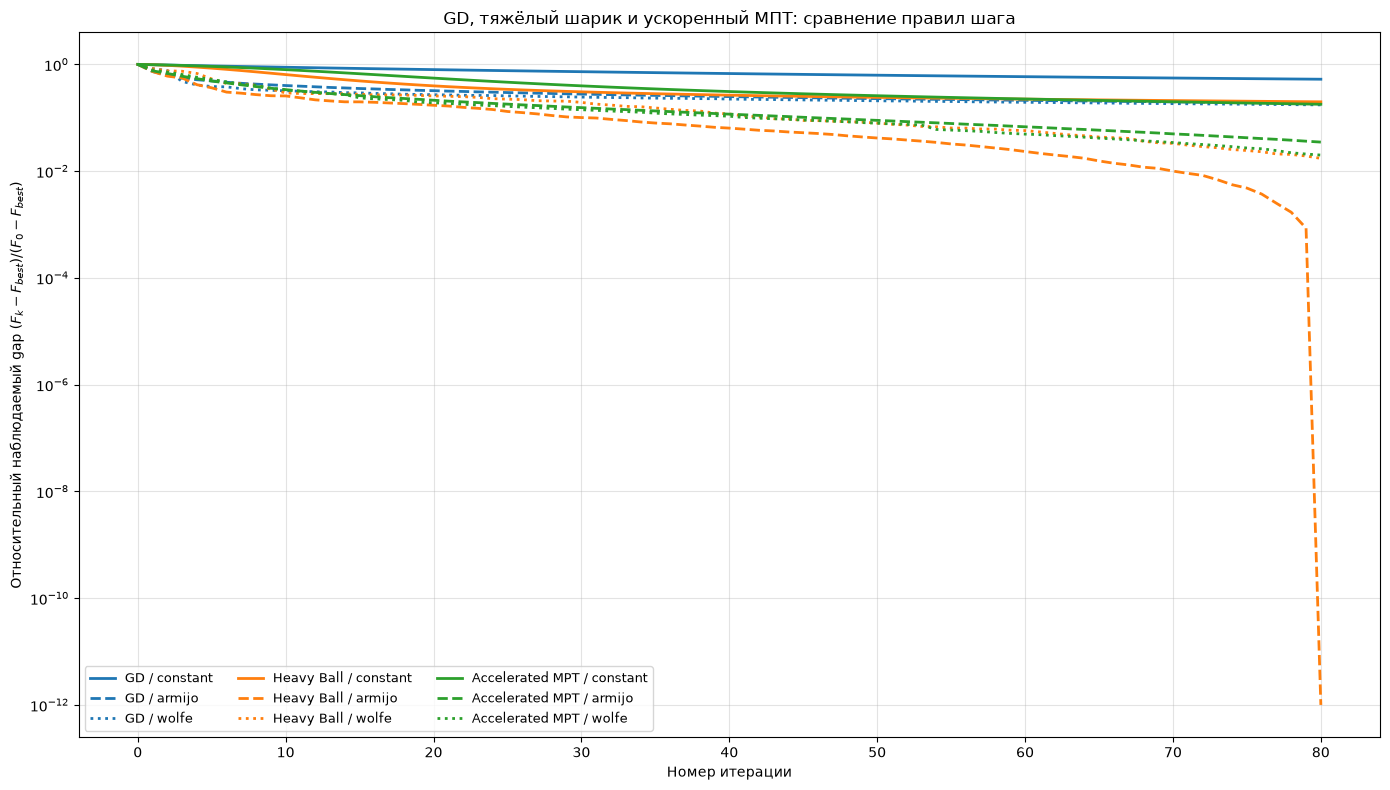

In [16]:

# Лучшее значение, найденное любой траекторией. Оно используется только как
# эмпирическая опорная точка для графика, а не как доказанное F*.
def finite_history_losses(history):
    values = np.asarray(history["loss"], dtype=float)
    return values[np.isfinite(values)]


observed_losses = np.concatenate([
    finite_history_losses(result["history"]) for result in results.values()
])
if not observed_losses.size:
    raise RuntimeError("В историях нет конечных значений функции для сравнения.")
f_best_observed = float(np.min(observed_losses))
initial_losses = np.asarray([
    result["history"]["loss"][0] for result in results.values()
], dtype=float)
finite_initial_losses = initial_losses[np.isfinite(initial_losses)]
if not finite_initial_losses.size:
    raise RuntimeError("Нет конечного начального значения для относительного gap.")
initial_loss = float(finite_initial_losses[0])
target_loss = f_best_observed + 0.01 * (initial_loss - f_best_observed)

summary_rows = []

for (algorithm, rule), result in results.items():
    W = result["W"]
    h = result["history"]
    finite_losses = finite_history_losses(h)
    finite_weights = np.all(np.isfinite(W))

    reached = np.flatnonzero(np.isfinite(h["loss"]) & (h["loss"] <= target_loss))
    iter_to_target = int(reached[0]) if len(reached) else np.nan
    time_to_target = float(h["time"][reached[0]]) if len(reached) else np.nan

    summary_rows.append({
        "method": algorithm,
        "step_rule": rule,
        "iterations": len(h["loss"]) - 1,
        "final_loss": h["loss"][-1],
        "best_loss": np.min(finite_losses) if finite_losses.size else np.nan,
        "train_accuracy": accuracy(X_train, y_train, W) if finite_weights else np.nan,
        "test_accuracy": accuracy(X_test, y_test, W) if finite_weights else np.nan,
        "time_sec": h["time"][-1],
        "iter_to_1%_gap": iter_to_target,
        "time_to_1%_gap": time_to_target,
        "median_step": np.median(h["step"]) if len(h["step"]) else np.nan,
        "f_evals": h["f_evals"],
        "g_evals": h["g_evals"],
        "restarts": h["restarts"],
        "line_search_fallbacks": sum("fallback" in status for status in h["status"]),
        "diverged": h["diverged"],
    })

summary_df = pd.DataFrame(summary_rows).sort_values(
    ["final_loss", "time_sec"], ascending=[True, True]
).reset_index(drop=True)

display(summary_df)

# ---------------------------
# Общий график: три метода, каждый с constant, Armijo и Wolfe
# ---------------------------
plt.figure(figsize=(14, 8))

line_styles = {"constant": "-", "armijo": "--", "wolfe": ":"}
base_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
method_colors = {
    "GD": base_colors[0],
    "Heavy Ball": base_colors[1],
    "Accelerated MPT": base_colors[2],
}

for (algorithm, rule), result in results.items():
    h = result["history"]
    relative_gap = (h["loss"] - f_best_observed) / max(
        initial_loss - f_best_observed, 1e-15
    )
    relative_gap = np.where(np.isfinite(h["loss"]), np.maximum(relative_gap, 1e-12), np.nan)

    plt.semilogy(
        np.arange(len(relative_gap)),
        relative_gap,
        linestyle=line_styles[rule],
        color=method_colors[algorithm],
        linewidth=2,
        label=f"{algorithm} / {rule}",
    )

plt.xlabel("Номер итерации")
plt.ylabel(r"Относительный наблюдаемый gap $(F_k-F_{best})/(F_0-F_{best})$")
plt.title("GD, тяжёлый шарик и ускоренный МПТ: сравнение правил шага")
plt.grid(True, which="both", alpha=0.35)
plt.legend(ncol=3, fontsize=9)
plt.tight_layout()
plt.show()


## 8. Автоматический комментарий к полученным результатам

In [17]:

def empirical_comment(summary):
    finite = summary[
        ~summary["diverged"]
        & np.isfinite(summary["final_loss"])
        & np.isfinite(summary["time_sec"])
    ].copy()
    if finite.empty:
        print("Нет успешно завершившихся запусков с конечным значением функции.")
        return
    best_loss_row = finite.sort_values("final_loss").iloc[0]
    best_time_row = finite.sort_values("time_sec").iloc[0]

    print("ЛУЧШЕЕ КОНЕЧНОЕ ЗНАЧЕНИЕ")
    print(
        f"  {best_loss_row['method']} / {best_loss_row['step_rule']}: "
        f"F={best_loss_row['final_loss']:.6f}, "
        f"test accuracy={best_loss_row['test_accuracy']:.4f}."
    )

    print("\nМИНИМАЛЬНОЕ ПОЛНОЕ ВРЕМЯ НА ЗАДАННОМ ЧИСЛЕ ИТЕРАЦИЙ")
    print(
        f"  {best_time_row['method']} / {best_time_row['step_rule']}: "
        f"{best_time_row['time_sec']:.3f} sec."
    )

    print("\nЛУЧШИЙ МЕТОД ДЛЯ КАЖДОГО ПРАВИЛА ШАГА")
    for rule in summary["step_rule"].drop_duplicates():
        candidates = finite[finite["step_rule"] == rule]
        if candidates.empty:
            print(f"  {rule:8s}: нет успешных запусков.")
            continue
        row = candidates.sort_values("final_loss").iloc[0]
        print(
            f"  {rule:8s}: {row['method']:10s}, "
            f"F={row['final_loss']:.6f}, time={row['time_sec']:.3f} sec, "
            f"g-evals={int(row['g_evals'])}."
        )

    print("\nСКОРОСТЬ ДО 1% ОТ НАБЛЮДАЕМОГО НАЧАЛЬНОГО GAP")
    reached = finite.dropna(subset=["iter_to_1%_gap"])
    if len(reached):
        row_i = reached.sort_values("iter_to_1%_gap").iloc[0]
        row_t = reached.sort_values("time_to_1%_gap").iloc[0]
        print(
            f"  Меньше всего итераций: {row_i['method']} / {row_i['step_rule']} "
            f"({int(row_i['iter_to_1%_gap'])} ит.)."
        )
        print(
            f"  Меньше всего времени: {row_t['method']} / {row_t['step_rule']} "
            f"({row_t['time_to_1%_gap']:.3f} sec)."
        )
    else:
        print("  Ни один метод не достиг выбранного порога за MAX_ITER итераций.")


empirical_comment(summary_df)


ЛУЧШЕЕ КОНЕЧНОЕ ЗНАЧЕНИЕ
  Heavy Ball / armijo: F=0.313393, test accuracy=0.8167.

МИНИМАЛЬНОЕ ПОЛНОЕ ВРЕМЯ НА ЗАДАННОМ ЧИСЛЕ ИТЕРАЦИЙ
  Heavy Ball / wolfe: 0.115 sec.

ЛУЧШИЙ МЕТОД ДЛЯ КАЖДОГО ПРАВИЛА ШАГА
  armijo  : Heavy Ball, F=0.313393, time=0.161 sec, g-evals=81.
  wolfe   : Heavy Ball, F=0.347854, time=0.115 sec, g-evals=108.
  constant: Accelerated MPT, F=0.669098, time=0.184 sec, g-evals=160.

СКОРОСТЬ ДО 1% ОТ НАБЛЮДАЕМОГО НАЧАЛЬНОГО GAP
  Меньше всего итераций: Heavy Ball / armijo (71 ит.).
  Меньше всего времени: Heavy Ball / armijo (0.142 sec).



### Как интерпретировать основной график

- **GD** обычно наиболее предсказуем, но не использует накопленное направление движения, поэтому по итерациям часто уступает ускоренным схемам.
- **Heavy Ball** может резко ускорить первые итерации, особенно в вытянутых долинах, но при большом $\beta$ способен колебаться. Рестарты в таблице показывают, сколько раз инерционное направление переставало быть направлением спуска.
- **Ускоренный МПТ** должен лучше использовать информацию предыдущих шагов и при корректном шаге часто быстрее уменьшает gap по итерациям. При этом значения функции у ускоренной основной последовательности не обязаны быть монотонными.
- **Постоянный шаг** имеет минимальную стоимость одной итерации, но требует настройки.
- **Армихо** обычно надёжнее фиксированного шага, однако выполняет дополнительные вычисления функции.
- **Вульф** контролирует и уменьшение функции, и производную вдоль направления. Он может принимать более содержательные шаги, но часто дороже, поскольку в пробных точках нужны и функция, и градиент.

Поэтому лидер **по итерациям** и лидер **по времени** могут различаться. Для вычислительно дорогого полного градиента это различие особенно существенно.


## 9. Влияние параметров методов

In [18]:

# Исследование выполняется с постоянным шагом, чтобы отделить влияние
# собственных параметров метода от поведения line search.

# 1) Множитель постоянного шага для всех трёх методов
step_multipliers = [0.25, 0.5, 1.0, 1.5, 2.0]
step_rows = []

for multiplier in step_multipliers:
    step = multiplier * CONSTANT_STEP
    for algorithm in algorithms:
        if algorithm == "GD":
            W, h = optimize_gradient_descent(
                W0, X_train, y_train, "constant", step,
                max_iter=PARAMETER_STUDY_ITER,
                lambda_reg=LAMBDA_REG,
            )
        elif algorithm == "Heavy Ball":
            W, h = optimize_heavy_ball(
                W0, X_train, y_train, "constant", step,
                beta=HB_BETA,
                max_iter=PARAMETER_STUDY_ITER,
                lambda_reg=LAMBDA_REG,
                restart_on_non_descent=True,
            )
        else:
            W, h = optimize_accelerated_similar_triangles(
                W0, X_train, y_train, "constant", step,
                max_iter=PARAMETER_STUDY_ITER,
                lambda_reg=LAMBDA_REG,
                restart=AMPT_RESTART,
            )

        step_rows.append({
            "algorithm": algorithm,
            "step_multiplier": multiplier,
            "step": step,
            "final_loss": h["loss"][-1],
            "best_loss": np.min(h["loss"]),
            "test_accuracy": accuracy(X_test, y_test, W),
            "restarts": h["restarts"],
            "diverged": h["diverged"],
        })

step_study_df = pd.DataFrame(step_rows)
print("Влияние постоянного шага:")
display(step_study_df.pivot_table(
    index="step_multiplier",
    columns="algorithm",
    values="final_loss",
    aggfunc="first",
))

# 2) Коэффициент инерции heavy ball
beta_values = [0.0, 0.5, 0.8, 0.9, 0.95, 0.99]
beta_rows = []

for beta in beta_values:
    W, h = optimize_heavy_ball(
        W0, X_train, y_train,
        strategy="constant",
        constant_step=CONSTANT_STEP,
        beta=beta,
        max_iter=PARAMETER_STUDY_ITER,
        lambda_reg=LAMBDA_REG,
        restart_on_non_descent=False,  # чистое влияние beta
    )
    beta_rows.append({
        "beta": beta,
        "final_loss": h["loss"][-1],
        "best_loss": np.min(h["loss"]),
        "test_accuracy": accuracy(X_test, y_test, W),
        "diverged": h["diverged"],
    })

beta_study_df = pd.DataFrame(beta_rows)
print("\nВлияние beta в методе тяжёлого шарика:")
display(beta_study_df)

# 3) Рестарты ускоренного МПТ
restart_options = [None, "gradient", "function"]
restart_rows = []

for restart in restart_options:
    W, h = optimize_accelerated_similar_triangles(
        W0, X_train, y_train,
        strategy="constant",
        constant_step=CONSTANT_STEP,
        max_iter=PARAMETER_STUDY_ITER,
        lambda_reg=LAMBDA_REG,
        restart=restart,
    )
    restart_rows.append({
        "restart": str(restart),
        "final_loss": h["loss"][-1],
        "best_loss": np.min(h["loss"]),
        "test_accuracy": accuracy(X_test, y_test, W),
        "number_of_restarts": h["restarts"],
    })

restart_study_df = pd.DataFrame(restart_rows)
print("\nВлияние рестартов ускоренного МПТ:")
display(restart_study_df)


Влияние постоянного шага:


algorithm,Accelerated MPT,GD,Heavy Ball
step_multiplier,,,
0.25,1.697178,2.119414,1.485595
0.50,1.390443,1.979926,1.166678
1.00,1.100834,1.763260,0.921692
1.50,0.967700,1.602743,0.822118
2.00,0.890720,1.480773,0.766864



Влияние beta в методе тяжёлого шарика:


,beta,final_loss,best_loss,test_accuracy,diverged
0,0.00,1.763260,1.763260,0.6480,False
1,0.50,1.488212,1.488212,0.6562,False
2,0.80,1.124209,1.124209,0.6641,False
3,0.90,0.921692,0.921692,0.6856,False
4,0.95,0.819220,0.819220,0.6991,False
5,0.99,0.781212,0.781212,0.6989,False



Влияние рестартов ускоренного МПТ:


,restart,final_loss,best_loss,test_accuracy,number_of_restarts
0,None,1.100834,1.100834,0.6636,0
1,gradient,1.100834,1.100834,0.6636,0
2,function,1.100834,1.100834,0.6636,0
